# Day 1 — Open real motion data and plot it
**Project:** Edge-Based Fall Detection and Haptic Alert System

Today you will open two real UP-Fall sensor recordings, inspect their columns and labels, and draw graphs. Both recordings are already included in this notebook. You do not need an ESP32 or a separate dataset download today.

**How to begin in Google Colab**
1. Open https://colab.research.google.com/ and sign in with your Google account if asked.
2. Choose **File → Upload notebook** and select `Day_1_Fall_Detection.ipynb`.
3. Save a copy in Drive if prompted. Keep the normal CPU runtime; no GPU is needed.
4. Click the play button beside each code cell, starting at Step 1. Wait for it to finish before running the next one. Existing outputs below show a checked example; run the cells yourself to reproduce them.
5. Finish the questions at Step 8, then run Step 9 to download your work.

**Today's finish line:** You can show a table of sensor readings, a walking graph and a fall-trial graph, and explain what the axes mean.

## The dataset and what we selected
Official dataset site: https://sites.google.com/up.edu.mx/har-up/

UP-Fall provides sensor recordings, labels and camera data. We use only the **belt IMU** (the sensor around the waist): three acceleration axes and three angular-velocity axes.

| Recording | Participant | Trial-level activity | Repetition |
|---|---|---|---|
| Subject1Activity6Trial1 | Subject 1 | Walking (activity 6) | Trial 1 |
| Subject1Activity1Trial1 | Subject 1 | Falling forward using hands (activity 1) | Trial 1 |

These are laboratory recordings, not construction-worker data. They let you learn the workflow; they do not establish your component's performance on a worksite.

The CSV also has a final unnamed column containing changing activity tags. In the fall trial, its values are 7 (standing), 1 (forward fall), and 11 (lying). We call it `frame_activity_id` in the extracted table. The constant `trial_activity_id` describes the overall trial; it does **not** mean every row is a fall.

**Dataset citation:** L. Martínez-Villaseñor, H. Ponce, J. Brieva, E. Moya-Albor, J. Núñez-Martínez, and C. Peñafort-Asturiano, “UP-Fall Detection Dataset: A Multimodal Approach,” *Sensors*, 19(9), 1988, 2019. https://doi.org/10.3390/s19091988

Use the official site's access guidance and cite the dataset in research that uses it. The embedded originals were downloaded on 14 October 2026; their source links and SHA-256 checksums are retained in the exported folder.

## Step 1 — Load Python tools
Run the cell below. `pandas` handles tables, `numpy` does calculations, and `matplotlib` draws graphs. The other imports help read and save the included files.

In [2]:
from pathlib import Path
import csv, json, base64, zlib, hashlib, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path("FallDetectionProject")
RAW = PROJECT / "data" / "raw"
PROCESSED = PROJECT / "data" / "processed"
RESULTS = PROJECT / "results"
for folder in [RAW, PROCESSED, RESULTS, PROJECT / "papers", PROJECT / "notebooks", PROJECT / "firmware"]:
    folder.mkdir(parents=True, exist_ok=True)
print("Python tools are ready. Project folders are ready.")

Python tools are ready. Project folders are ready.


## Step 2 — Restore the included original recordings
Run this cell once. You do not need to edit the long encoded text: it is just a compressed copy of the **real CSV files**, not generated motion data. The cell checks that each restored file exactly matches the downloaded original.

In [3]:
SNAPSHOTS = {'Subject1Activity6Trial1.csv': {'activity_id': 6, 'subject_id': 1, 'trial_id': 1, 'source_url': 'https://drive.google.com/a/up.edu.mx/uc?id=1SCxR1FB-EB-ije3aPDV8YC0C2Dipadow&export=download', 'sha256': '8c769500ff2ffe4dc450823bc30c0bce35174432d36fb2211f7553da155c98d3', 'compressed_base64': '...'}, 'Subject1Activity1Trial1.csv': {'activity_id': 1, 'subject_id': 1, 'trial_id': 1, 'source_url': 'https://drive.google.com/a/up.edu.mx/uc?id=1-qsLb3ubU_MZ5-TO3e-AAg89cgBzEPZX&export=download', 'sha256': 'cd13cebba52174d49512d0ceed2fafc0d97489d48253867a4916f5005321c297', 'compressed_base64': 'eJztfUvPLMlx3V6A/oOWEtD9Od8P7eidAcMwTMFej0bX9JjDoTEcGpR+vTPjnIjKenSza2DAG5PAvXe+rx9VpzLjceJE5D/98Idvv/3luz/8rz89fvPT73/89pvvv//247ef//iHb798+/nx4A9/+t2ff/zu5//67cc/fv/DL/+qP/6Pf/7DDz/98U/zJ//lh9/9j1/+8x+///23X46fsP7q9DnLL5dP+/fffjx9jPzs9P750+WN/+nb978/vlF+dnrj/Onyxv/28w9/On0lfnh6q/x4vdqfv/vhp99+++lPf/z58R9++u8/f/fzt3/x9q9g/4r2r2T/yvav8vjtn//5f377/pfHb77/5Yf/PT/4n37+4bsf//ZvHn95fveXH/70d3//u394/Ov2z3/b/qkv+Jdvv/t3f9pexP/8t/1//vDjj/Pav/vp+29/9/c//uUf/v/H/z/8ePzvb/8mON+erj5d+icf/tGlf/T1q8YWS388/Zdz+eG+Qhj/4b5ci/OvUv34WWrt8QxfZfzMzZ/2Nn8ayvjD9fbwX7W0+Qmtj5/UGMar3JdP8/etzw+Npc7fpzI+NH615OXjQnjEPv6O/KowP2/8Of6j+TxfGfr4Vf1q48r6V3D14UP0XzGW+WkhzVfmXOWqxxfU/NVyeqT05cbvos9ffXxM8K59+fnz/PCn/9cXqHSX3Q6VBlTCvKw0r258dZr360O4RCV+xfGl4z7lta74S1TGF8Rx6bjkJ5B8C0r/qnncfvty49uzfPtbUEL7qu2Rs1xtHNjMKzBMzoC8hGQskzIe7QZJ9HJjtevDnE/YBUNGMKny0iZ30f0AZd4KMak9ApNxgROTiUysUZAp9qq5+BZEqny5a3KfdX75vLb5et8E8fQVxxJeMWl4cWkCSvaPUMdf5dHql49jodTw5XzYQInhxkppLYfyEpZcZKn78bznw9GVgpt0c714F+ev+ris8ZfPsujGahNglrUiC2Eub7zWf+WWd7iEKhgD2dwEjzzXlufqE1Tf4yJA+nFXc6vHXGTHbriMJ/QxLj3lFCJwaYtdqbKD5MIG7FWuPU7kLoHJWAqCyHOxLXtg8PzSgCJx270DJn21seBwr9PGxP0Oyr0KKrJR/fhc7x4RltCHIhvUEHmm+DEkY8e66lpbjUqEaSjykGhlvdyWmAsxKlGMCi5mXNn8pW9Rze0DRmm80M0/41g/5Ssmz8USxgccto+gkQK2zzDeNMsee7jIulrxcOOpj9cGl2Sr9nH3X3mYmTSueEA7IGl9QSR0dwOR4mRdXCHS1E9kWbwwFhORPq1uEDy6uiWxFeNm57Oe91cmat2rLRmPfGIXv7r8Yl73amTjxMRHGNlp9tNXj52ODzZ5Q2S8RP7Msq5CnDvbYUXTYcUubzdM2g1EvEsx1XXbAJCgXhaboE07egEHVnUQuzZu11d/iQd+MzyrmKX5NN/CAZMTaJ7CV4r9rwASaJPVlMsG3rxOuYNIGp5hIiJGCkZk3A6eJeEYazCox+mRrs/J0rULmZ5yWp5O2yp32Z04HYF37njZh6HqC1dUinxiFZPZxkvhub1YdcY2O0yCmJGUm8QI48mNz4pjFdIpwLJtkPgbhsT3NiOMIyRpfJunecBupglpiw8eS3k8fXE2csNFbuMKkfBVUxLDkOeOmHHDikcXO+KxSDzdEvbpEyC+hyNOc1/Go5smaeD+K7EIyQdPPxPEVNKE2AZgiLWL1A6IBAkxn1kXSRoXJpBIRNvFZkZxHRJ8eVtNc7+/AUXMZ9vMz3RNO9vaOvYIVmtSa9zEK02I5FkaMDl+Dkz0PvES5PoRGQou6SsPR0uDglUJXOT6Y4D7LRp9jdeHaQLhE+fv8hKwtaD2xsKXeQsrKk12TjF7kuHBCIvYhl0MG8XOBYlL/FiDAV+AeP7ZsGQMlR5ugFIGhvkSlM1iuayh7BqUJLmLIDHDjL25JRDEXKECnyBu+hzGllZWUOIDmDA5wre/xyTLR3Zi6AHmtlTcDROb/HjyDqgkteHj6ubTjF9FLYzfXMoVLFjrHokakiTHqGX6Hm/BmiR+WOFY4O9wYboFC88ltgIzk4cJjEdaMAw+nRv39PCKiPcsiv04uB/AjPik90tgNP0Te4edTdsiT6hJODMXe8Fui00clsdSdpo4DuMSaVy4zYYhlB15BqXTrqQldC5q8HdmxcEGCvIzVfKOborLpTVxb1tqfGOx5HH9iXalCCZFl4fGVwX4i5ldgtjaGYp4JgBcW3QdF5AUhuHTx+OWT8Y2F0slxTzQn3DzvQMl8EI9HtCzYQH/KruSR9Rc/LJQgnnl8TQlv0UmuNnaAyZPZK/MFTWFdlgtcmfTT0Q+bUeU38DBwC7zJpE1rh4ZewwrdRr7DIsyLmSGB5XhvaKR6+dolLF/e3iBRiv6RBlJEg44b0lvYF6Kmocn718WSN9ilCQZjyQOWCAnRgngekCir3uChPgAkdK/orgrgTCmvSEJNzZNyVUioA2RpokO94kaEpeuEbG9IsEMfOwVImr2JOA+bZkjIvA65QvRzPzuHSBZ4qYgKYbzM8LMPvATYpVA9ldtl9JLiu4SDjwjbEVyhYRDjE0S6yoLWhwCUn/jEObvsuCRZL9spAoDYoF5h8gD6ZVY1synAad9CEzGp2b4GrypjZvXvG/+WbJcxJb2XdFrLwCpKY9ceEn7PHdMJtOjaUYtZlPBNhbGakaaCUv7Gg5Ylg23uc/e4IEHMYFP5uHfIeJnTtllmTRwjltIku4AMjZnx1c6SXCVGZgJ1CTvQAmtYdoBkCRxiEK22VNwI3JTMRv9pB5VPnaHh8Q3pQOQpkYL64Rv3tMl+EyvKXlDEgIn0w+Umvftc0xabFFJ6RMm0214YX7MOAgoeTMibn0FiFqjYA+owOJqDIW7vEBFfte8WdOs6d+Rlr5AZeZYHpxdh5/fds6NEK213NXBg/QGJt02DugtMF9XmOxDfnvlBGWJXFOjg3mCWcOW+CuYTFutdNwEdBe4etmN4t79sK2z6jB3CPiBVrHMbKGEG6lfT14I8jMmSmnxTpHQnTCJepP0vMznV5IAC+VB48rfn5ZJgbNoYAC8rjgYKTFpu0WCxJn554QL5AR2XDrErM/PEekjLhr33Zat4xG0Vm/EAGOsjXgFu9I2RBiSwIqmpjwSDGy2ZIjBF1zacZHkupgToatr01TyGJHAOwoi6UEKu0t1g/UirJgtIPk4ROvjlkL2+RIQjammxfRkhzbSREgeB46cDx0M/dxsAEQCEqHooyTAUtuwjOWECNYIAo447bZ8wAwt5C07d4MUKPqk68pnhDOkFMIhhn/6egeU7HwCl+S3bVPVe7CMUiwD7vIq/KpbVMs9A1N7hYglSDSuRzqaawRMY5iFDdeMqIV5+iug8BLIkUas1mXnpBtbZ7jhqgUuhCbNrIkmfmvF7wDKEkqtZiQhq5GwJCVjmix6ncvuHSZkUXGjSKt2G8cjcLXqKaMBfn5E+XTbOR8Tjn0SjmZKDngoS6IWBXe7Ba9iTObeYZaHSIY2R2vDzH5RBJhP/Kl87ZGnZ6xGhzMsr6YI84XHzXPGBKhptpjSvmjhy8fR2sCkD4dSF4ej4Ws37wo7sdZxXmGCeo/Z1yMoFsDOtJrR/TtUSE5OFpv1zRWTgOJWkb3TpFwgYZIkF6lL0LZhcmPbjC8oSpOcIVl8yIqIbB3JcCb9JzsHK3YJ6BFMiIGKcNGCBwzw8yLBCWtEP7ACewnzhDTgLSIsDOJqsj/Er3cQGftWDUlZopKy96079YBssIoQ6eFY9NT9dY0Gi6OMS44kyRkN7C2p5eDPnf8VSGdN30kM6zW/kugoYQNv1OINX5Oin/X0KzSY/KrXsYhkj4aaTKsLKi80qytWDxZACW68juVl1Rkk8aFWKYiN3kfy87MEkRC5basUXTVfx2ZbotYbRiTV6nxZ0xsqZ5IF5fpwp4HjlhFIUFSydWSQqGG9RMTc9dH/tvowQ96cxu4kq06VrSMgsqJU0CEE0uZm0o0FMu7Rp7AFI6hhyWUhCDQnP63+NRoamqHMYckeWVaJ4RkBIx5v+hXv4QDbKmKM8/ogI5AsKCpe7WneU4o1fUwZDTiG9ej1Eg7yLrJsZ+yzBWgwqJLbyFKUO1SJhcUi8uhY5Ktq/Lk6zv4F/hO2Zm4XJFOI4wHNDo5Cc1o1j0ANEVqFwHzIFsjnmW+fmXOPCESQVneakDyLWZZhEXWakIdGALMsA+Onupmg4poDHsg1TKIkd7suD+BB37OZYEraVDnzDpIs+5FalYNNfYbPedaBSRsmm5iI9WosTkQL4mXT4OKuMLHSbpeKOioysp/G45ZyMMWMoRmZfbKoB0jMAkO/tAMD/kwWnHdNZS/yZI46kmf6nFLs47s8ZWcnKJAsafljsabySIIU9iYlwYqUKTZXSpHqq1kZIMcCG32Bg3kW1SRNQ3q1V45YBGxF0KtJIjjDIuYbMXutkUIWJ+SCZrtSapdiP54QHyguRhiRjEValeFC7SDDOV6AgRoB7+2k5jwCog7LYrJ2kC46ICUcgxRFIwwS/GxC0Ldku+WG/WghJ0qNjqBIQYC5UoV5ucQEezXDVDY6opnwir8VTIYxQRRN04FPPSvSQMU2WapzlTB3vUjt4LQBSdHQmM4uwowt1uMMx2tAanLIKZyoeHXHVFUbwWg/G03llgIy2zV5lkhmsoUfezhU8QLPIuzwLtOVG0Omo/qIsC3Q+dzfwSELlAk/1WBGq37MNQ/D48f/l4yOa6M9MnmhYLTVJRDc5LawNV4HfSh/xoElFTeM02H03kCB5DAYOz3/a29BAIbxZciCmcEAw19RsBpwFB+9u4BDEhJyWwwswIIggmYQpJGKiqQsuZVkr3UUMvvCkjHeOpJlDhwzyLJEnwbFM/OFt3CALPNMNib0Syb3qT0NsxboEwtCCD0QRU7SGdGEse7BylVSzQxYH93EZcxxN03EHhAGdRrbSYKWwsgV0iUeVGSFKME+rav3bSYpuFyxFL5CuBDnmpAYmXsS4XosXYrAPn+6QoK4ez7iEySU2GnyshRn9phoYYH8BlyRMSDyECc3nnX1Uykwo7sVkyTumwFqUWo0IsgadyoKmjeYPLPoQqP6JtmWBsrHRiRIGa5QPgNMqM2rEOwiYNg1lpA8BPfQuJg0kVmkVgdINLlleQufuGISBZMCSzIpGFMJKRnLPHbFBfbc470zqsyRNHNVnjJWoaEMnfix7GrCU0JqfYnQCgnnyZpKUGYRWsvXABWT3Ll9FTy1LYafVhXUoBU5pxl6i89YP8I604c8A/SqGz4zGpaX9wRyoc1UonFfp86Glgh5uOITbqyeYZqKb5fwGEsoNMwawVZUbQoNLx7PE7qFJQUOUtSTaD5mUo/UNQvYCzZZdqanF5phSif3GEEWPgtWxV/BZmqiZyxDJVvHmw2ZZ/w0tg8i+h1LB5GKIMNAJagInjKRVWAjmrUImZxpYQxBVWDtgQFgEHpgqb0FJhWqVyVfqKx5LrB0qBgTvNlsKQhuWoJIgUElL2+g+E/DtzDXfok1XYKiObdoHuAcLkGZ5aS5zKu6HfNLFfUK4Rl9e6hWhj0TB2SKmHGft7pnRsYQwfw2FkBXZPBOJ1mSyBeQwj87TGBelsrH7UkTlNZcZ0lLHhckPTO7YqsHeGNqx5coX3aSlyRsGpcCE6MKtmkXlRmDDR62ekoQmqDbxA+vkIS1gCMFQVYoaCkSo7l1E5GdC5qWjD2koRZcFBX1BswNfz3il6ohTOPtCDBZt4NSYRrtWwk0Qjc+62iSHzc0BC4yRo8oRrgBSWDnC3wVM4MlvoNGqMPUNYjxbOtjcBwQ1LxHJhewfEFr+2SWLJa5sZFyGNFd36J6XzZoipUZBgrkEQCNUAcO6t35qKCn1r4m9KIBHHFNspPmspouAQ4elnFFRooQkmlSfNO0c2xuTLx+xYX8U0Jj29zthYIXOMDUdrHMx+z0jBJCqMFpUQDxkpiXZM5x9lKI2j9bwixbThggaQiUth3mIdBZCiJirxog8ZtwxWcVbOxsixbM5v1KBCnZN7QAXGkrJJApFRDiM7Gliw6IYRrJN8Wk3sGk5Ajhv0MrLL4jC0XN3BWrUjkElNXR7aAV0qJaP2ioL/BgqwoiEnZ0bYiwRZYbQ1NqkBIjZ9vtG0/hBYzglNtEBjiwWx1WbHFA/XM4qg+JGs0jHFpgUoURVHx7NGhvlIZvRENqIV14xrGSVay8KqPfYKHbDy0tng0xKyK2b5xI6Uc2IssXtqrjr82KuBvxWy0xs8LFjAhwJLUiKkZCjmiiC1nfraq65csac7ZSThNhUbDGitmkxHJw2O8WZhyofbeZ8XExVQg9IbN6i0gHWRzgqBpo6g2SSxrBX0PS/LgPOh0YEZa4GprxrBrZLW0WpRk06zUyMLGeqU3VuIclMNnzEB+SJngHS2wUDyBiHvG7KJJWXDIsmhA4k/zODNbo0A475xYsuTaGsydYaNHgdvzS53dAxjtWgdCKpBjOXYgrlpLivCqtZJiXL7tcCKuUyojZieb55ZE9BS6/x8UnlueKseuGyiVp/QKVPmDVeDZv5gRZkPB7oCP5dQsoYBRGYM5eeOF70H9yhYj44Cc88XzpAkbj82A1dYp/KQSA2WzntFm6csdfsFsTsIhocL5HAvBcQQEYpXBlY1+BkrJr/goUeAft5Vh19HtM0OXA9L9Yq73UvAIiNonVxJ5Qritb/i0sDsT/E3W5Rzla2itcZp+9PBkS5B1Jwq/aQr2XAIfroCg1/bjEHCRSvCWEXjY/SP9plKs1QRqC1sB1gKZo46jYnMlQ7BxQ3SLGMp5sR46QkTFFmUaxwhIcWHMU5+dSoAJ2bNDCZodI+n3zyldu6BIZP9dGpJJcaAGvoX2bznTG7+z8i9o8HaGrxpZWfySdbcKzFtiNQum5k8ZN5sxTWEdFou9KOuztS5Hke1IacyHNyRySccKme+TOu8wQtjqgr3nS+IXzVrzSOTHteEuh6MBDuYd7j85YuA7ViDM64kyhun0mmN6X4HCkxlOvaamQify+SaQap0+hNQg0X+ChXwMUka8HhDCRiqV3AFXmqtxPspDk4o2lm5fxMUJpuFWEMWVRyghdgFC/yyWbGsggKjCwmfF6VPE9U3rlPS8gQve5Zn7nJSSmzzEvmjoCqTVpRw4K/itEBdU1FCunYctkozMJoCy72QBKk534GKBeQ87XAFHmr33EiL02hKSwFYVVmX1MgZUMj0E+VDGgt1YmfkgZf9aNlAdggHMi7c4I4Q0Ji4+6ixWijFjIS6iaRjSSmSdFzZeQ0iyEXaufgxRSaBX7DEVgZKitaHLEKS3PJBbyNUTkhHHf0omuEEkBoZFyCITQw3SeKSq3aBRmWoSSL17tz2TvGR40jXljwsVwLejkG3sstJ61XR72hxUq5PxVAnWxL1XVrYqP31oB/XAwnW6Y9adF1bKHhy8An4Bg9x06sOURSiMMUFjRidS9UPUbtM1X61Ye4Bo2wvV+iM0wCCWnF9iwgYY9zs/Gop6iQwpKFg9bXWeQRPvo41axR/6Q1GIFZCLsRQF3sjC/tT6sMLuocNEwxyLjO3gip7aw2Y8CO7M+d9AZjohJJlpfPVq0ZSQEtRLcMh2RzWtwMA5K2byo9AysWm2qiQyMA3Qogdsb54ziTGZYM+UR8wXsnSO1t4ATelUWb+6sOVBnXnVGL1VkWmPppnCcH4KTUuq+XoNDLZ6GrY7NegZOlNsFky4TE7ABPaefYQzZJTxMl1irFwLhHTxkNCI4ei9o7fCpCGVFDJCnag2mpiJ+SOFAUdxZPamXDNflQZNxi00Cd1y1qheKDhl6BQ69kM6Q2UYziTy5gGBG7omIVgK2E1uRxEg5FO/znLeC1mMPtM9+/YRNgDalwlBFpi8bfXMDm5x8oWoN6XhEe5boVeAgknZtOE4IUoAqa9AQiEZWXvjqQvrrAh5E1pGsYT2undBQKmebWNALKEqvSYPMgo8vut7H1zyabOmKWAl040Z73vBWubVZ571GBh40Iqf2vXNICIHJSBwlRZsOL0tQJBX5ZqOJ0AYdxVnNeo3PnEnEzMuf/NUJmMhgBYkBGgtf4uI5z6ZSTgafsqUTNyzOWK15qUpYT30eTzyRKOKEJd/KPhqMLIEhUx/hf9LWDUodlMEQfqZv6Yd4KhUpAptZijzsLUhFQI1OaVPGVmF4x2rFihFq4sxz5u7mwBcOaqB92yXrH6JUS6/QlslYl3F7dKhzqyMiBy85DAX7QAHSTJfZRIccqTySNcJLN0/tqsly7K0vrEHn6W8puWistwakIrvIRxvsYdoKvJEStvs6d1TpDVUeOcKcz2F8CBoiJZ9mgWT6yocwjcCy/d+CKXKkjvZI0YIJTtFJOzl0Wnl2QFjIAFl3xpsXmFgsxH4bN5+gkjSPcYyBrpCaKhJhLr3qPFo9cMvuxqJqefxUmJ2KikODwH+28JS5G7zporxXxbXAFVDag1mY9mPmh1YD9+wHuURqDlmF8sZRBdrdLiCyIRIRqY5nX5VErYUUyZyf11LY4dU4RStMVlyKrcq/cOOOxUvjumWtN9Dq3cMFn9DiwJ7ZJJiERA+IeWxxOUilAuYsCMUFfZJqx6sKpSeh6gM1nMMcJfLylYlui7vQ+hKsgtseawFrnaLot1g1dbUsi4SChtptYd1IXXtqoRqj8VS1UBzeI6q+Rm165EJ7BVXrwrgV82gFudsVWqWS6FKdjUchZkOrIkErcovSpVVISEYNU1pePN+8dDROgbGT7+Kq8qp0mvcgbtCW1Y1N2HuI3V1iVTtbUHUcrNI1ghUCoClgw3zb6cob+OEpHAIT4ShWx+4TNxvQMZVnIKz7IgDkOfrXV/8Wr+GtITPx8rU7tJ5o/xDfYWGm7N15+UXJWX/g1j4OpMK05DlgyiXsj+jQZRpjgyDlmXR+UddZAK/QyjBAgQYppLrZLdT0IqVOs6arSwMTfjxuKvSxBrBOKEqWxViGnU8qYq+MSkEp1rGDGxK4C6y8Dal0mP7EMcMedr8lguQ+gKrlkvIVVFNBJWWERMimAHjH1fog6ViUNTA5sUTqtepSbH3rhzlj5WxUJPhL9L68xipTpRHZUowHYVANk4t7QFF7+lfsQQ5HeXL+sAH1vAPUCNsqOjDkdrPULVID4cwxhaj/NWyP1zA9E5PdQjOnNtghWWsWtQ5E5g5Xc8OIDLt1AypkE+94EbdTdEASFtTAG5i85wy5hL+hJttg4tb7DKbmMBQoC1MK+U6e6SRTl1CJVgUZrRsvsHkYEYOTDkRK1QLXScBeeYGSl6vO3KYRi2oBCfEVt/eM+0jEdhIzfIzLzusYIFArBoiPd9INTOJfRmo4soYKFUmUj5AKw3mK4uuEVOPGyw0DxSKKoYpUYrc6QukuZLu02md2bC/TrVxlpzydhpe5gTO6KdhEqkx8B1QBC1gpqGFM/BYo0D+FKojodbw1LVS/saLCCKTAz2M6k2rbh2dlfFspaCtwVC9xqiiCcfd1qH5sh2LG01xa0vsJQr8gSI1I4zaQuPpQB+hzPTeE5lyj00bFvR33CV8i8iOwvRi1L5OyqnYncs9lGe78IURx3DCG22To1x9QfM47RlriCoenLrSBjZjgbUxCZerXZeYY+/2pJbvGiBLLgBJjPu04VNrCkqA0Dr124lUmUAtAnAdaEkZPTjTE4HWdcsvRGkBIYtePAWoxobvsABAHVj471vZMGFJduANHRSSHcATEwBOaAuKV0YFbXDQ9aRZbrYV+ORCARPE7hIrqLRmawji9Q8nDjDHypwTC1pHv8XOYRqiXMT4SUt3Odp5xPZ3rmmcb+IjY4x1QlTGzrKGyNBtc4KTkuCONDQZnA0o11+LnwIzKatAsEb0ri49zkRUFebu4YzFFOigqrx7Oz+X8OUot1uguUapI12c1aSoOil+zFvdFxbSPUZksDjbIkG4WTJMBSGBrvY1YyUhuY6KOTuzFa4SijrOb0S1WxQoPHkEGRVptUI7X8XeylRWfVm4ESnk4IcwTggvx4ImEcHTcy0H4j6CzQBWfIMPHQWI4bMzZRlabZwtVXiKAgORUHrT/koaXEjhrEfVyvwu9E7CZUzHm/XmhlDB2m40FEVWsHUyYR0WSOanif8ZgMqCRGgIFKrsbVru44DKK0Gg20YrRiOAKPWbLX+suuwIoWkO8BHudS2imMiju4ik0HUHJpA/7eINHeknQ4DPhDDZ0jw1LIFXfYeM557XiISUb08jYKN6wRCUnjxamiAa9iIZl0faYEE5Yw+b2FSYoZT0kINV5O1iHq41W+BIhkvfIc2nhiJAsNfEbnpxFwCE4M9pxtCiLnRbhoePcyAQiXji8zhEA6NrZbBAZzM/g6S26dg1PV5GHFkE5uszSETLnEJnJ3Fr4cc5jyNZFSsY8kASqOtS/IauVe38LD1nUoPkX48h3IKH6X8Ff2RkgdGbBkYr7CKSaQsLQIeo+OzsSJc4BByR2OlJ6+xIh6H0SVF3QDVzjwzCu40bpozaEWJ/hEHKZmM/4g6UXCpgXhHJn1ChJZ5YygYQAkcV2pGzbLnOp3oCohwxPcAERAzrq/NJah0s45yWh/h58MJMuhSF2pDi1t067sWts7LFJLDqikv4WIuPiQScfjPQFRHPmz7haEnDx6OxjurHThiv17JzGKE98GToLSHuTDjtUui8woiAzcRLBMgEBrR+g0XqCAEekMlTMgHhZ9hrGaEGN2YWlgRco1ORONBaMKpKPLFtUrlIoIw02Ean92o3WWmmo7JwwSlG5Q1KOelaJGmvUYdhLImNsOFyarOmSpR0xcpbu9m0S64oRtFocNxrEAnuuZ48Wo50pAoMLLQmOzBBtE5cd1RlLZC2L6VOMeh2eBbccBKTaTKnVGbvjNJu61wQktDZ2XF6dZQENoqC/DlpxQuMJKDzxz7NjUhZotEECa0DkGnwcfTwzCNZyGCivALEKzPk902eKeS56qEjRoSEKUPk4Q4vzYVUMP5i1NXHgmDwRtjPphOwsaBu3iKhs4noheAtV6ZTJl22geYNAhMHLjG9A6Grx6pBzHOEhDe7F/IOReY+OMQgoNjO22PZY+DjnmLccOmZgYCwHhqt5ngMhHAt2QWICaMXvuHVGOhkki/zBs64bOLPsoUoh16zA0sn7ooSNRHZLOMCQI3YSc4hl6Rl2gEdY40VP+YlU2Ku9HsHEeXd9TBHFGUDj6AwHQ1LxAOPikeFe40FPckYHQS9W9tw3XUdcQTzBwb7y8Akg06wj20jNgSzlafu7FvnnIsI9r8sHebNYuE0KTi1AYnyi4KT8seGJU2iAJuMzNlQR6oyDuBOIogmKU9cixELzolmJDktj7wkaVrfZxLtG0VfIoEGkcIqPiCYWYFzTRzMvQ4hjkuYsn9asU2gZAfmPSdg447opuUFv4BNTPiVo6Q9yCkx8kO9t6HCsEHP/2ZMM6VXggZjb8DyHOXeIdFuxQXFPPa1k77iwNxgCTYQS/VawGS7zdt9DxB3pOdWp2IQa5vMfp/NTKN5TQjMUQjgezDPrCuzxx+ROJKyvAYqqpMHFYBzzNUDk/b3WG9GwtwAETR3+6nVShLggeWCI1leAOBZATIQ8YdEzOMQW0Y59YnyYw8fx4bTpHs2jJ3ieOk9D+F1OvlJ0sLta5iQQCcWEeIG8CL0KCHqg6uZu9JZUeTv9cw0Nr8DxUPtbL/FaDLoCR+UGFaScze8lPLPA9Dk8fZgfphSU8quiTJsM004zYnxad+S/vFKbrGuYS5eU0z9sqzgUOQRunIiGxHepk0FBBuKiz1dwWAYgFa5lhSZQ4TQfAdalHM7QNQ+UHFWBkZkUn+KSUmkpXOIiV8G5CVnl3i+xsZncHDC8EfaX2Ex7yUEeYm4XKhoxe8XVSGe/rCztdZkOccXGU/0myyY0bcngaD9OhDFwSvg4nxjg9JAKpXtgN2RPReuEf4J0z2vpfr4aeUcnq+4hneHlixZSNxUHV2GLyFkoTbhhjCuVkt4bZJ7ZDjGw6cLvoGEOxICw7SnDp8/lhsPKcRgNRLswvjqwdP4XG4BAAO2Ua9fgKI+Wk1ZZruEBLQ2qYp+xOxM4Y+Kf1/kDT4ThSDDXRJRj5SAhrEmH0Meu2Ufyea0UXm6qF+CUkZM19wIc6sB5OOGhJy+xYxkzd2eBIcD6befnWoGejAYy3p7N6FQO8hVd/YYPh1xwJki2MdMcJd32cfI0NI3xF4U1OjQcMQWd4hLuXFLOrxAqrfPQSp6eUbbej0AdFGLloFM1dQGxayVxmGa1OSleZ/5oa55D8yc7mCtua4aQTtmM/hYhNrRR7gF65R1CqmCTuFMP99iKFzfwqaE46Kw8OqkadTbSG4yOIQ6/lZ4EA4dz4SnZmXstsjMDE2VYkoeq2Gkk16ueRqHDcPfI9K6W/MmhTzo0HXnXgSysqAvg8LfaovY4ic8/SBXidYL1CpeaA5sqz7ho08EkAzC28DUqXvsssfqhAr7ERc8u4WE7e2+FL5/Wk4uF6uBj0Z3mJnAsLRrLhF+hYDcenPidzdRGWJsoL2DHaFNXoZopVEt1KL7iEkhvZkOJZBM0GVpTdhhdwelGPdkQcExw6fWs2wAmVj5GioeLeQsLh2JQUUYFk3nvW6iMyIa1JBQlOsedygQaMWU6TWYXE59B0bVOl68z6I6Y6BAYkphLuMdcDhMgMMRMJD4c8nZMEzjbXOKm0r0drMspbxzXYa7pOt57gUoProQXqLBgY02AaxoekZc2JuqxqX5aNVE4BfKhbonzPXFeJpRQqrpvO/qGYyRJ9ng9YxxJPhz+W2wobOCX5D2BPEnLG9jM+Wowusr7y61ImVtyfcpvDjlmDDQvUBbGbjSPMsI6qwMdC2zS6F0nRHKTsoD4Ghv2r2BMpNQt1r2EBxk9Eqimp7xHDl1Bcfmv0qKX2KSpF6R2+4SN11HyOFuOefg7cKR0XfTYaj378ggOvelu+qvbDAxPkpChHmKbqYdFh6jMlAUunDAt5xI5m54Z2KbPVoaQZ4TlRTG1sRL+r+OSS2fdh5muo3BwzoWGsk0PjMbxmkfOrytKbObV7M5thgYUJ4xZN9fP46XtFIgTLsoVZU47eg+KTKfjd/Odhgnm9n+KiXfBg2SFq0Vx2CGksnMV5jM4VGHOkFj3BacyYzzOBSRPszJlObCN/LBEdUibIqfBwCFt6hXDBd8tG4xFoRl3Nz0SW2aGGi4puDu4SEL5Ahd76thL5Jo2ZOrilIKUD5HnYjfpcdSy8pbKZdfplTakbFlXJ2g0xEd4zFnDb8DhAMx1I2/Y1FhvYBPc2OzgFhCut6pVAJ/1WFsOPS6rqplddSSugwwXwV3UpUWd+aRwG9U4LKcji4OdtLsk2hl2NzLMRey0EewEpXEwbcXhemqknzptVVgxA8X3dgeU8Umot51AcexLxqlwiy73GhJzj8tBb5eQaIsvzwjRsWRqWzj9TYL+oNIUKs4vVorMCUX/K85U4XHHorbaQMl3dtG4EbZ3Yo5clw4UWYIsmlDht+AB8Hj8QmRY4fSoDBtniHMCFA05YtNvY4XdNRI6QPgrq1V5D4QEVzo+XEp9CkQOd2AYFloFB4gPou7+JxwJR0BlPUJu749hOoOAJ/oq43F1pDlmtTpUIrp6Gs6MNXFOALhan0THM0swmBqq5UzdMIG0kWwYso7ip4Rs55wNxWQ2Ot4ApbfkX4CCKAwloXrwOydMqFww02ZnmB1B4al1mJzGwyQnKEjAODwyBy1P6IRqvOEtKnoSF8QFbh+lBH/HIaeWqX4MaM7gQpdahZ6uho500NBX/jhgDCEGk3KipQ0axolWCguaPeZQdg6T1VmPulg4TkdE81h2DPv9eQeVxbzKaECZDYVzSkixKCqp3XE5ObrIUj8IeYw/dtos/eTRjscghTMSyNG1buEJk4S8rhb4YuZC5aHCUO4hjVHOsHCk09OKf8p2XsOitZKg09+mJE5hqeFORDt9DidO8Xw/uYekZ7kyQjlUSyKln50RRrNJ/Dwf0w72PmHyVDaO5xI/nJ38zF2cikVE2t102kAdTDjFXLHpBIQnu1Z4iNYW5t/xOSWOSK9fYRIYVTVy3YelcgGKkHE8MWHzw84ON523kjUX5/nfxmgGBHc8LKJA1Cg7grp4qnbe4BL40dSzcca3ATNHg9wApvYGVjAwXMLAyiw6NIwu1Ww5n4DpPP7XFSrDt1MvTaTvZIgDRxX1GlQOnHmYhEUoJ2R0vF5QLx6seUY3EQy+TPz+mkFNhlnxnPId2OthVvdO8FZDSbjqMzQUyQkl6/UMl5fYUCT2xP6LkH1eQcO1qOefmHnBVBwqzl3aWgWbbZGyT5qRKHCoZJVOdumKjVw0XOi2aOIdd1RrYptGwNqpUBG1oIfJQ1CmPRJadGzMgbDeRBmOKQ+a2JhgGIYcfJvvKh0qp6D2iIseoaOt0u1oZQ64FMTJCSEPm2wNlH4DkxbHIkiMT5+Oh2FK9TwhleA+T/uBKzwytjHOlIcLYgCqKS3hW+TCcrzXc/G8HnOt8ivOUOKE2B48K2nYmptcXwMXVBnnEHAvh8DGptPgsa+kq2+L9eMdX9RajiiknVDxeurM9EZHu3sBCudP8gxyO7v6iAqnMEJip2OOcMC1R7be5xGKPG4ZHt8D8AUUxEFQ+nWc+ivmTecjcL7thsotHqGHRmmrHpKBlt5olgK+shxEZkgLmd9jPhomie9O73OcnKp2JahkQ920VkrOqKBph827smbeQKLziUPWgOKwUtIdm9Jr5wkHJ0xsHGXbzlFbjAoUMJGlPKkaeT0S/bkdkHgCxcZS4KxVO/KqYxAved+gOQQnePOkjg2XjN5HtIDMlF2PbKKuj+KRX+Oe8/AysYFPZYCLQ1y1SkaqAg0UrxFhisx4SvPlGZ4hF4K/ampEno7HL9phPSdIdGwHkkNWkt9holZPzDIeysJOfm5S8iTGMpVAfZFwS0GcHLkenrkUP/Iax3G6tpQZQ9tOqN3oFCZZWRMrOVpyS5lRlnZpwUNGEtamB/Et+wYshxcXOTkJ5Oncu9QALYzk55tmdiuXgjL6GYvCE5qkG+/giS/wgPKNnOTC6V8Ash1F7bbhnmVV8aa29E7I+QgqoHoFyqTxhSHWiTuUqhouzd/BpTYeK8HmPkwDnuk85wkGGxZ4kQR1Jb+jptfr+TwIUJZD3HvSw6+4Ll9iwtOwEPawnLCAQklNlkE7pVFIpuOm4RoW+1o/j2bznBLQERGcINHWCoGkLcMUxHxQrMFAO5ngm/1CdgLRCZKnkYusB6g1QRiouEhGAK2dh//2u0pH4RwZSbhF60b9ijExUmI2WPLnUdtAZRgT6lD0KGvPxPCpzVxSo923vl2gwgFDfbFzSIXVvKJowfheB/ItK2VCErlU6KShwbOxCi8BwUrS2IGpjzmcWxYl+pHRM+nBli8M2BBMoZt/HTflOGtMSxtdBaLKW9aUNEeuC3GAPjGcbacH7tohGkc8tBALsimbYkEhoQxB2HVp6+YcNV85RImp45bvfE7Vyu3QqR5BocDYkSx7Cwttq54X4U3XfYTFeO1V/cv86rmVe3xTPQjJlK00/xIWGGVfdYD9ITa5USWcbXeRrWnUaHe2B1Q91EgvfeEj5XWO9qDBPbDXzG3tR7tCcrOihhWQbN+cEZFXcgKQyb0Vj0zvJ2GJT0pxcXXtSbc5y+8GGLVSphYAes/I7TdOlufNikxoWyNIdPDwhzXSQmVhfUvPA2S9lIxQs0N4ENfbSfHUgkBG5eTWatAR+eRBFzyUU5bRWqIX53Dq+Zt4sCP9Dh55wICk7ISHNmiw6rLTJZ/xoM4SpMkbOMDKATQ91ljRaEopyafkFzWvExpkJxA2s5j6a/j7gcZYHJTU6cG3DytQbodOrzvFU1UJl127aVf2XInYj7BhIe2ciPVK0LO3rsF4Fp5GJVnB3ueSyZDTmho1CFRZiRh487Y3UCi+9hKuUOCh2PiSnTCHVH1Tg/HkhOKo59cm66s6wYA8URqItyVBkXGwOiiWOaUeoAV2SOCxFSyKxKyIx1Xtqxe3MrtSYobrCJnxmGwQO1tVVUK76SgXgPCcqIV833PRxQYckD2zI5lOWHBcFMvpJ2dyQOKJhZYfp3JwuLMq6jAsbB0hv4F+yU2uYYfm4hDUAzdPClgazZnKo0Zu3kQGS2hpS06gKtVs65L3s+THHGfbSBLAQMO8Wgtcs3xeC6a9YGntsDSeUxd+A5PiWnqBiVJbLGxf1isWTNhGwdhq0T4eQNHVIXBsma6jqjvpGnHqHrb2hpeIwNlpDyJY8s2A3tktAw3Oa6Z6GLpEhw+GbEyL1vuEboeH5fMmHNGmXsb9WhaOCjAR22IwnoOHyrhQIuAxvYV3B9FNoclrQfcNlqlnNHOol6d6hwxpLYfMRHcLH9mqzkcp5PDeiBxAsZPAOGU3KI1YNotqp7Rp+PUGEsY6qGjtHQv9mWiPKo5Wl5Nms3L8v4Z9z7Mrn+MtjzhQu0n5WbhQfVJK53VJW+He+plPOOgu2oRYdd0mmXwAzIc4zPcQSCMVu2g5zXChUcsdIGrufSt0TrdSyAip2hvWscbwDgqqYdiIso/L1bEsm86kTNdo4NEy+dDhnIoHw2Z5SpiMibwR7dBSNt80aZ9THnNbOp/SJRZUNKDA6Q4tGDSiaDeJHjE0Kfnd9kgL4VE0NFC1MGvDTg8Qc4FuYYIrB0NQxFRlyHvF4K+JKPtiRNjTzM8yUtSULWfZajfkaGUaYI73Yt0OJyk7o79V3nWpDDA8OJxVHeMbPCgihwnaCr2MRBF3xMwalzkzGXH3BhCn/cJWllY0wo0Cb5mHaESGYFSiVUUDAQKs4l4NzQNaK4u7eoDI05qqizfih57KjOrJdJ6hMEYkgnKZAfoKBZYziJjwsI+VY1nFHxsU7XP7OaAolWMVDlBQJahFr51KkfOK2rJ9OZcur3rvPRS2KNDTbEiAE9AaQ9I2IyvSyEnXr5F4qoVntyFKUcTiGevnIrQyj5j3uk2s+dlxOgGCxgqpq9/3nRzweG5EOxzyZkeRqiAxLqrDe48HK5ZijCDUX9HAl5Kh85qrMZ1GeK5g3JGwlilhZbPwSzBoRA+LA4l8o3JmE9BZFGHF/hMaizR2RYTx+SYpYs8KBemim7owGxLqi3WDzQfQEBMRk+Q/pwPLPOwsaal/yWMZSdIj7kY4XaCx9vzulsYyIgHBBq63rHGHYUEtE1+ghSxMhXoDBXN+7R+FxFkNxw0Va5kqVsd5tAcsLC7nfR58CgMO7pKyBRt0QcXv8PDb4gDlxaKtNQkcAWEUB9+Nx3G1YZDlpY1W2ayIISKC388R6U1DPI4+wViKbA1ztgP2bbGa2sPNeK0WYAE86ZOuIVkEIAsk7PmEOEZauEUzpEm19LS8gWSNFFXvoDbkhuC7zPnJXZ1LXU2IKUvZM4Fg7y0gRomsSyRt4XmxZE0lD7ZljnA8QQQaqXxaItSoI+xQRYFfTgZfbOoNNeIApEfKkk+AWIhAVe+u7BRDWBFZjEjC52wm9QgJslh/6JMAIskEkZ1DHrpaywsjIndfEbRDCq/nKfkVkPo531G+cuyaJmv4YWZEr5ouN7U3gGjIxgDE2sj3O8bq1osruMJj+6AOsq9fOhgDRDcMlvQBj/I53THw6FWVzTvZVLQrZ2CxT+s5eqCbTSV5TkHKuj6WSTNgCJfdYs5I9wyOPHEWedvA/XnY3QIIDYgmtmY6xCIZFnKOysdQlNRSDldQPFcNwtmacmUspThaXeYkr6HwRn8uOS3nEqqgOT+0SFK2tfYOiyUalKhR0bgVppeecqUlZXEM54Cyym4Pet9hdcRCt8kSKwMKgxbb5HlIW7YM7gjGNgIMj3xm8LutUlbfolSSMbVrLOZv9ACUeYhGZZ3pjIhI1tVw7FRjpMB4IopT0pg59nN77idM3H6ByC4pq2dJ+jvTfh8dC6WzWBsYIW/5G1fSFo3dij1GbMc+lBDKGntsSWK4Ijz8Gox5lT5cRB47MLYwDOnyRhrvstq0xjCer36Hh0VhrMjt0hd/C5A24lxajyMgWjIMlqi9B0RCLKY6xzJk3EKxpfaw2NEjIKx+aqZzRGQfr28PD/Zut0DqnWi9tZ57W40pak5LgYDpy14uppktDUhcjAcfrBaVLhAx92qJHNGwEhx3HU7nlULWOzDMS0kdTgqH5mZvCBjKJI0rRPoadSgd9lzKhs/jdIkjFha9pu0opZU2TlvUgXjD2dCISzi0zpU5i+Qq5AAWm8eWE+qpXreQ4/NCQpn7uEV3iQVuzDoed6dbH3aKU57PWhiOtYQFDLaRhy1E2OpNbLgQB4tmFyljoda5sx0UCiQG6U9jGyHIqWXNbD8GpE72uuvxEiSPIa00c2Grdj87LOxMR9DI5GlxymY8dtY0P9bscJmWoCW4YqmtjZIqNo7nHSZObfMhJs2fFxZmd8+4df8KD3z8Fny/hWOhmhcdv19CdN0rz/NmuQBDJkJpqH5kgbTLDylE2WiJbeFtvuVzW1one1yxdXn6CuVPZdGU42S4fdXJL4OqI9650IPPRXp7hcjOkMJuMAgzs72vVLzFgueBwe6KHMaguNEQVGfzf8fglcBJ4qy/NfMNRGTvZ1Xt09XPbqMIFh36Yj6igYGIFEtp06nDlCppWrccgYOKDiQy2X+6Fg0ZlTOC3Nbijs8z/DrL9nwiSgJhtxRVS/AxH5KWCzy0arRWUNjzQl4NE3rKFodp2HEJR8/GN4LK2OFB7losh3ASctDFF3uyJav4Nf5lANJGwJMuAbEVwtDjsET6CRKWqRmVXuOx0aULHLAdTO87Xdo6rPEdFmrY0PnbV8cSP09o6zB4rvHwX796Wm3DKWZI935F1wYNR16SFdqczbFgsyyFOHUmx50S61ZuIRjhMmVh3CHRTtUyla5L4bptXaTPay0DjRaomr9CYyEHjwTyFRxhRUNb1i/QYBSPW91kDEdITJsXq+XJKyg8kIGgbHsaedDiVT6nwmZ3plPLwcGQOFM655Mx25fw/b6EvzV6WxJveob9hLyNhXWHIgPCWfJhcaNGYGyOjMcZDhIuW7i+7ZhyZ5GklnQ7+l0NyqZUcMPvS1BnRHainufCIPc1EtMCgDuoa68AgToPE2p2YAALeVrN25xFts6s1QU5cvJjKHLIFaM8rqDYqPoj38FAoy17p29G/bnd5BUWW6v7sji4W7xRQFQy8KDAr0PscQAk6KhDyWsxRUUNyFz4NxAZOZxWF2BA4mZAsPTgcPecxwUgqt4gNW/kMTJaZi4apj8/QgTEMX3uifeAF4AWseoo5ac+QAkNNqt6Qw9VB6rdpfegbIOETrFpteDUaDGIA99gsihpziYkabSui0ld/cGiHhF5UtbK2Rg4f2cpuryK1/8PSbjQZg=='}}

provenance = {"dataset": "UP-Fall", "retrieved_date": "2026-10-14",
              "official_site": "https://sites.google.com/up.edu.mx/har-up/",
              "paper_doi": "https://doi.org/10.3390/s19091988", "files": []}
for filename, info in SNAPSHOTS.items():
    original = zlib.decompress(base64.b64decode(info["compressed_base64"]))
    assert hashlib.sha256(original).hexdigest() == info["sha256"]
    (RAW / filename).write_bytes(original)
    provenance["files"].append({"filename": filename, **{k: v for k, v in info.items() if k != "compressed_base64"}})
    print(f"Ready: {filename} ({len(original):,} bytes)")
(PROJECT / "dataset_sources.json").write_text(json.dumps(provenance, indent=2))

Ready: Subject1Activity6Trial1.csv (328,069 bytes)
Ready: Subject1Activity1Trial1.csv (55,247 bytes)


852

## Step 3 — Turn one recording into an easy-to-read table
The originals have two header rows of different widths and an extra unnamed tag column. The helper below reads the CSV safely, verifies the belt-column positions and units, and extracts the six sensor channels plus the labels. It preserves all samples and values; it adds elapsed time and readable names.

For today's exercise, keep this helper unchanged. Later we can unpack how it works.

In [4]:
ACTIVITIES = {
    1: "Forward fall using hands", 2: "Forward fall using knees",
    3: "Backward fall", 4: "Sideways fall", 5: "Fall while attempting to sit",
    6: "Walking", 7: "Standing", 8: "Sitting", 9: "Picking up an object",
    10: "Jumping", 11: "Lying"
}

def read_belt_recording(filename):
    with (RAW / filename).open(newline="", encoding="utf-8-sig") as f:
        rows = list(csv.reader(f))
    header, units, samples = rows[0], rows[1], rows[2:]
    assert header[15] == "BeltAccelerometer" and header[18] == "BeltAngularVelocity"
    assert header[43:46] == ["Subject", "Activity", "Trial"]
    assert all("(g)" in x for x in units[15:18])
    assert all("(deg/s)" in x for x in units[18:21])
    assert samples and all(len(row) == 47 for row in samples), "Unexpected CSV layout"
    raw_table = pd.DataFrame(samples)
    selected = [0, 15, 16, 17, 18, 19, 20, 43, 44, 45, 46]
    df = raw_table.iloc[:, selected].copy()
    df.columns = ["timestamp", "acc_x_g", "acc_y_g", "acc_z_g",
                  "gyro_x_deg_s", "gyro_y_deg_s", "gyro_z_deg_s",
                  "subject_id", "trial_activity_id", "trial_id", "frame_activity_id"]
    df["timestamp"] = pd.to_datetime(df["timestamp"], errors="raise")
    for column in df.columns[1:]:
        df[column] = pd.to_numeric(df[column], errors="raise")
    assert not df.isna().any().any(), "Missing values need investigation"
    assert df["timestamp"].is_monotonic_increasing and not df["timestamp"].duplicated().any()
    df.insert(1, "time_s", (df["timestamp"] - df["timestamp"].iloc[0]).dt.total_seconds())
    df["frame_activity"] = df["frame_activity_id"].map(ACTIVITIES).fillna("Unmapped")
    return df

walking = read_belt_recording("Subject1Activity6Trial1.csv")
fall = read_belt_recording("Subject1Activity1Trial1.csv")
print(f"Walking: {len(walking):,} rows. Fall trial: {len(fall):,} rows.")

Walking: 1,133 rows. Fall trial: 195 rows.


## Step 4 — Look at the data
`head()` means “show the first few rows”. Each row is one synchronized observation.

| Column | Meaning |
|---|---|
| `time_s` | Seconds since the start of this recording, calculated from its actual timestamps |
| `acc_x_g`, `acc_y_g`, `acc_z_g` | Acceleration along the sensor's three axes, in g; gravity is included |
| `gyro_x_deg_s`, `gyro_y_deg_s`, `gyro_z_deg_s` | Rotation rate around each axis, in degrees per second |
| `subject_id` | Participant identifier |
| `trial_activity_id` | Overall trial category |
| `frame_activity_id` | Supplied per-row activity tag |

`1 g` is approximately 9.81 m/s². These readings are already scaled in the original CSV, so no raw-integer conversion is needed here.

In [5]:
print("Column names:")
print(walking.columns.tolist())
print("\nFirst five rows of the walking recording:")
print(walking.head().to_string(index=False))
print("\nMissing values per column:")
print(walking.isna().sum().to_string())
print("\nActivity tags within the fall trial:")
print(fall["frame_activity"].value_counts().to_string())

Column names:
['timestamp', 'time_s', 'acc_x_g', 'acc_y_g', 'acc_z_g', 'gyro_x_deg_s', 'gyro_y_deg_s', 'gyro_z_deg_s', 'subject_id', 'trial_activity_id', 'trial_id', 'frame_activity_id', 'frame_activity']

First five rows of the walking recording:
                 timestamp   time_s  acc_x_g  acc_y_g  acc_z_g  gyro_x_deg_s  gyro_y_deg_s  gyro_z_deg_s  subject_id  trial_activity_id  trial_id  frame_activity_id frame_activity
2018-07-04 12:09:23.419628 0.000000    0.125    0.909    0.526        34.451        -8.354       -33.232           1                  6         1                  6        Walking
2018-07-04 12:09:23.469262 0.049634    0.280    1.057    0.640       -31.463       -24.024        -0.549           1                  6         1                  6        Walking
2018-07-04 12:09:23.513885 0.094257    0.280    1.057    0.640         1.220       -26.524        27.927           1                  6         1                  6        Walking
2018-07-04 12:09:23.561011 0.141

## Step 5 — Draw acceleration graphs
Run this cell and look at the two panels. The horizontal axis is **time in seconds**; the vertical axis is **acceleration in g**. Each coloured line is one sensor axis.

The red shading on the fall-trial graph follows the supplied forward-fall tags. It is not a new prediction from our code. The rest of that trial includes standing and lying.

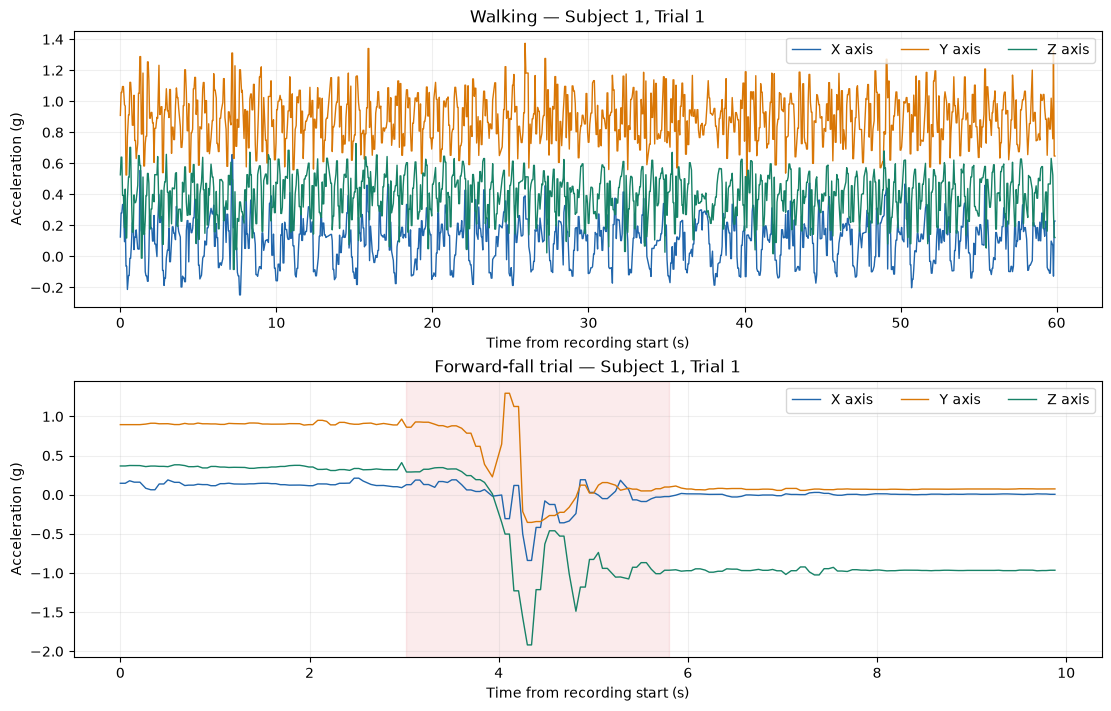

In [6]:
def shade_forward_fall(ax, df):
    mask = df["frame_activity_id"].eq(1).to_numpy()
    edges = np.diff(np.r_[False, mask, False].astype(int))
    dt = float(df["time_s"].diff().median())
    for start, stop in zip(np.where(edges == 1)[0], np.where(edges == -1)[0]):
        ax.axvspan(df["time_s"].iloc[start], df["time_s"].iloc[stop-1] + dt,
                   color="#e05b65", alpha=0.12)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), layout="constrained")
for ax, df, title in zip(axes, [walking, fall], ["Walking — Subject 1, Trial 1", "Forward-fall trial — Subject 1, Trial 1"]):
    for axis, color in zip("xyz", ["#2166ac", "#d97706", "#178267"]):
        ax.plot(df["time_s"], df[f"acc_{axis}_g"], label=f"{axis.upper()} axis", color=color, linewidth=1)
    ax.set(title=title, xlabel="Time from recording start (s)", ylabel="Acceleration (g)")
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right", ncol=3)
shade_forward_fall(axes[1], fall)
fig.savefig(RESULTS / "01_acceleration.png", dpi=160)
plt.show()

## Step 6 — Look at rotation and combined acceleration
The gyroscope shows rotation. Acceleration magnitude combines X, Y and Z into one value:

`magnitude = sqrt(x² + y² + z²)`

At rest, magnitude is often near 1 g because gravity is included. A peak by itself does not prove that a fall occurred. Today we only explore the signals; we do not set a detection threshold or train a model.

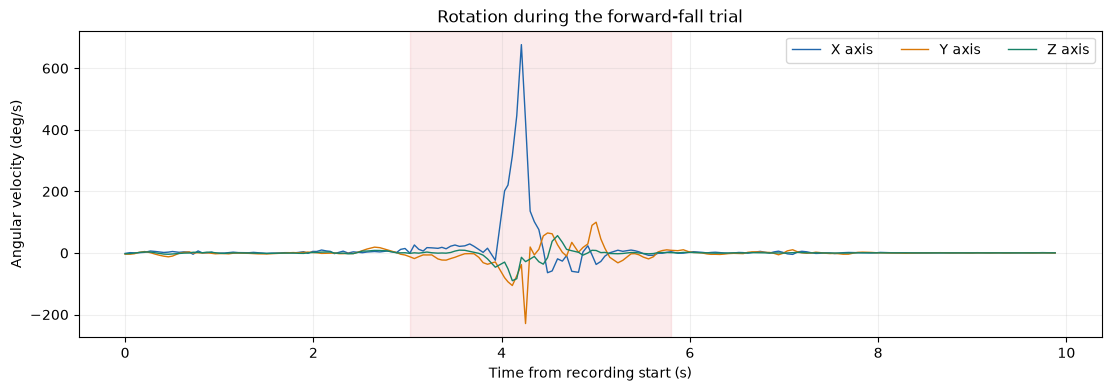

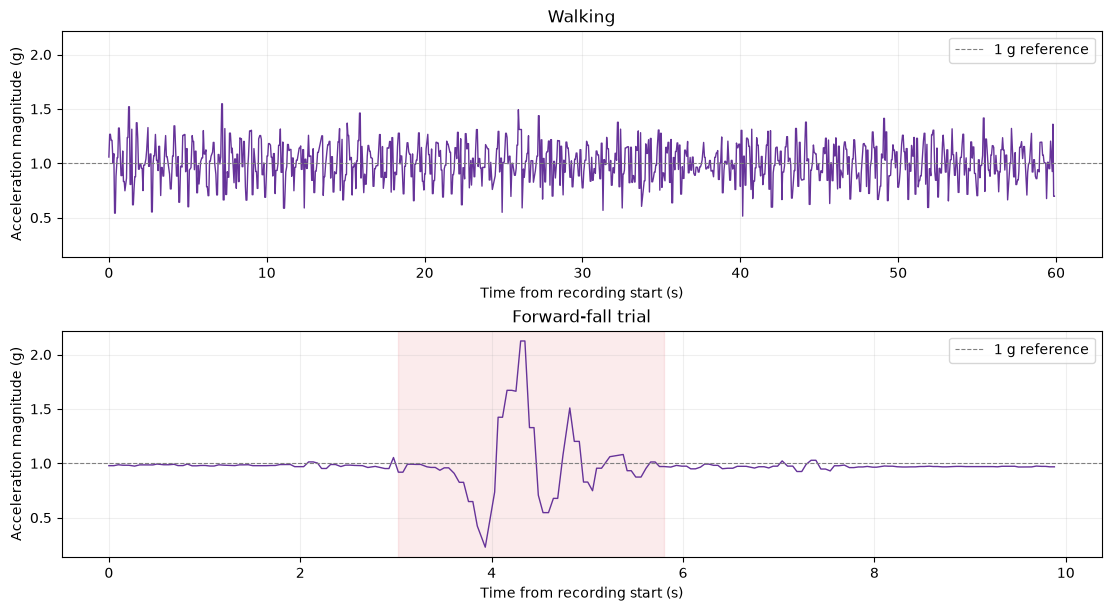

In [7]:
for df in [walking, fall]:
    df["acc_magnitude_g"] = np.sqrt(df["acc_x_g"]**2 + df["acc_y_g"]**2 + df["acc_z_g"]**2)

fig, ax = plt.subplots(figsize=(11, 3.8), layout="constrained")
for axis, color in zip("xyz", ["#2166ac", "#d97706", "#178267"]):
    ax.plot(fall["time_s"], fall[f"gyro_{axis}_deg_s"], label=f"{axis.upper()} axis", color=color, linewidth=1)
shade_forward_fall(ax, fall)
ax.set(title="Rotation during the forward-fall trial", xlabel="Time from recording start (s)", ylabel="Angular velocity (deg/s)")
ax.grid(alpha=0.2)
ax.legend(ncol=3)
fig.savefig(RESULTS / "02_gyroscope.png", dpi=160)
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(11, 6), layout="constrained", sharey=True)
for ax, df, title in zip(axes, [walking, fall], ["Walking", "Forward-fall trial"]):
    ax.plot(df["time_s"], df["acc_magnitude_g"], color="#663399", linewidth=1)
    ax.axhline(1, color="gray", linestyle="--", linewidth=0.8, label="1 g reference")
    ax.set(title=title, xlabel="Time from recording start (s)", ylabel="Acceleration magnitude (g)")
    ax.grid(alpha=0.2)
    ax.legend()
shade_forward_fall(axes[1], fall)
fig.savefig(RESULTS / "03_acceleration_magnitude.png", dpi=160)
plt.show()

## Step 7 — Check timing and save the tables
We use the actual timestamps. We do not assume these synchronized files are sampled at the proposal's planned 50 Hz, or at the raw sensors' nominal rate. The rate below is only **1 / median observed timestamp interval**; it does not imply perfectly regular sampling.

The extracted CSV files retain the belt data and tags and add elapsed time and magnitude. No rows are filtered, no values are resampled and no model is trained.

In [8]:
summary_rows = []
for name, df in [("walking", walking), ("forward_fall_trial", fall)]:
    intervals = df["time_s"].diff().dropna()
    summary_rows.append({
        "recording": name, "rows": len(df),
        "duration_s": df["time_s"].iloc[-1],
        "median_interval_s": intervals.median(),
        "min_interval_s": intervals.min(), "max_interval_s": intervals.max(),
        "approx_rate_hz": 1 / intervals.median(),
        "peak_magnitude_g": df["acc_magnitude_g"].max()
    })
    df.to_csv(PROCESSED / f"{name}_belt.csv", index=False)
summary = pd.DataFrame(summary_rows)
summary.to_csv(RESULTS / "recording_summary.csv", index=False)
print(summary.round(4).to_string(index=False))
print("\nSaved two extracted CSVs, a summary table and three graph images.")

         recording  rows  duration_s  median_interval_s  min_interval_s  max_interval_s  approx_rate_hz  peak_magnitude_g
           walking  1133     59.8941             0.0481          0.0366          0.2184         20.7771            1.5470
forward_fall_trial   195      9.8807             0.0476          0.0361          0.1138         20.9961            2.1245

Saved two extracted CSVs, a summary table and three graph images.


## Step 8 — Write your first research-log entry
Read the graphs, then replace the three `TODO` strings below with your own answers and run the cell.

1. What does each row represent? What do g and deg/s measure?
2. What do you notice about the walking and fall-trial graphs? Describe what you actually see.
3. Why can't we say the whole fall-trial recording is a fall? Which activity tags appear in it?

Your learning task is complete once you can explain those points. We will build the threshold baseline in a later session using more recordings and participants.

In [ ]:
answers = {
    "What the columns mean": "TODO: Write your explanation here.",
    "What I observed in the graphs": "TODO: Describe your observations here.",
    "Why trial labels and row labels differ": "TODO: Write your explanation here."
}
from datetime import date
lines = [f"# Day 1 research log — {date.today().isoformat()}",
         "Dataset: UP-Fall; subject 1; activities 6 and 1; trial 1; belt IMU.",
         "Work: loaded originals, inspected labels, plotted signals and exported belt CSVs.",
         "Scope: exploratory work only; no trained model or measured detector accuracy."]
for question, answer in answers.items():
    lines.extend(["", f"## {question}", answer])
log = "\n".join(lines) + "\n"
(PROJECT / "research_log_day1.md").write_text(log)
print(log)

## Step 9 — Download your work
Run this last cell in Colab. It creates and downloads `Day1_FallDetection_Work.zip` containing the original recordings, extracted belt CSVs, three plots, summary, source links and your research log.

Also save/download your edited notebook from Colab's File menu. The runtime's temporary files can disappear when it disconnects; your downloaded ZIP preserves the work.

If a cell fails: stop there, copy its error message and send it to me. If you restart the runtime, run all cells again from Step 1.

In [ ]:
readme = """Day 1: UP-Fall exploration
Raw CSVs: original snapshots, unmodified. Their headers have different widths.
Processed CSVs: belt acceleration (g), angular velocity (deg/s), identifiers,
per-row tags, timestamp-derived elapsed seconds and acceleration magnitude.
No filtering, resampling, model training or accuracy assessment was performed.
Recordings: subject 1, activity 6 trial 1 and activity 1 trial 1.
The final original unnamed column is exposed as frame_activity_id.
The entire forward-fall trial must not be labelled as a fall at every row.
Graphs shade the supplied frame_activity_id=1 interval, not a model prediction.
See dataset_sources.json for original links and byte-level SHA-256 checksums.
Dataset: https://sites.google.com/up.edu.mx/har-up/
Citation: Martinez-Villasenor et al., UP-Fall Detection Dataset: A Multimodal
Approach, Sensors 19(9), 1988, 2019. https://doi.org/10.3390/s19091988
These laboratory examples are not construction-worker validation data.
"""
(PROJECT / "README.txt").write_text(readme)
archive = shutil.make_archive("Day1_FallDetection_Work", "zip", root_dir=PROJECT.parent, base_dir=PROJECT.name)
print(f"Created: {archive}")
try:
    from google.colab import files
except ImportError:
    print("Outside Colab: the ZIP is in the current working directory.")
else:
    files.download(archive)